# Experiment 01D - Collagen to Diffusivity Mapping

Loaded collagen fields: dict_keys(['Uniform', 'Patchy', 'Band'])
DIFFUSIVITY FIELD SUMMARY

Uniform
Mean D: 3.500000e-07 cm²/s
Min D:  3.500000e-07 cm²/s
Max D:  3.500000e-07 cm²/s
SD:     0.000000e+00 cm²/s

Patchy
Mean D: 3.500000e-07 cm²/s
Min D:  2.500000e-07 cm²/s
Max D:  4.048007e-07 cm²/s
SD:     5.247424e-08 cm²/s

Band
Mean D: 3.500000e-07 cm²/s
Min D:  2.500000e-07 cm²/s
Max D:  4.055280e-07 cm²/s
SD:     6.193320e-08 cm²/s


/var/folders/sj/6mw6cz_x1dg1nlhv9xgk5rgh0000gn/T/ipykernel_99448/3608568368.py:108: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


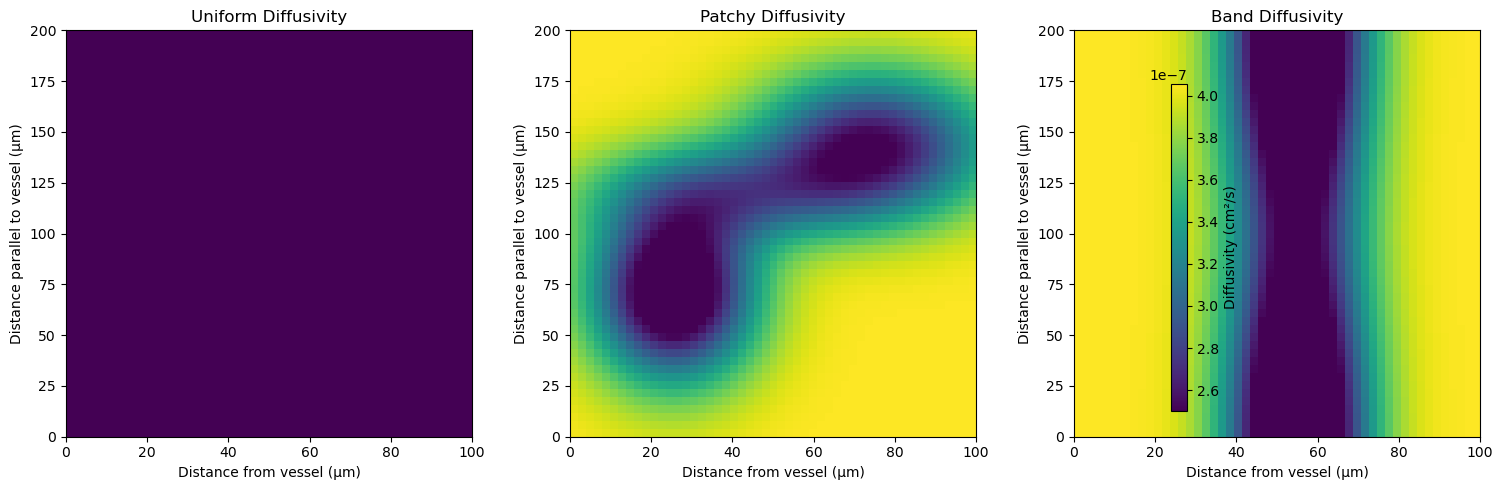

In [6]:
import json
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# EXPERIMENT 01D — COLLAGEN TO DIFFUSIVITY MAPPING
# ============================================================

# ------------------------------------------------------------
# 1. Load master parameters
# ------------------------------------------------------------

with open("Parameters/model_params.json", "r") as f:
    params = json.load(f)

# Spatial parameters
Lx = params["Lx"]
Ly = params["Ly"]

Nx = params["Nx"]
Ny = params["Ny"]

# Convert domain dimensions from cm to micrometers
Lx_um = Lx * 1e4
Ly_um = Ly * 1e4

# Diffusion parameters
D0 = params["D0"]
alpha_collagen = params["alpha_collagen"]

# ------------------------------------------------------------
# 2. Load collagen fields from Experiment 01C
# ------------------------------------------------------------

data = np.load("Parameters/collagen_fields_01C.npz")

collagen_fields = {
    name: data[name]
    for name in data.files
}

print("Loaded collagen fields:", collagen_fields.keys())

# ------------------------------------------------------------
# 3. Collagen -> diffusivity mapping
# ------------------------------------------------------------

def collagen_to_diffusivity(rho):

    return D0 * (1.0 - alpha_collagen * rho)


# Generate diffusivity fields
diffusivity_fields = {
    name: collagen_to_diffusivity(rho)
    for name, rho in collagen_fields.items()
}

# ------------------------------------------------------------
# 4. Validation and statistics
# ------------------------------------------------------------

print("=" * 65)
print("DIFFUSIVITY FIELD SUMMARY")
print("=" * 65)

for name, D in diffusivity_fields.items():

    assert D.shape == (Nx, Ny), f"{name}: Incorrect shape {D.shape}"
    assert np.all(np.isfinite(D)), f"{name}: Non-finite values detected"
    assert np.all(D > 0), f"{name}: Non-positive diffusivity detected"
    assert np.all(D <= D0), f"{name}: Diffusivity exceeds D0"

    print(f"\n{name}")
    print(f"Mean D: {D.mean():.6e} cm²/s")
    print(f"Min D:  {D.min():.6e} cm²/s")
    print(f"Max D:  {D.max():.6e} cm²/s")
    print(f"SD:     {D.std():.6e} cm²/s")


# ------------------------------------------------------------
# 5. Visualization
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (name, D) in zip(axes, diffusivity_fields.items()):

    im = ax.imshow(
        D.T,
        origin="lower",
        extent=[0, Lx_um, 0, Ly_um],
        aspect="auto",
        cmap="viridis"
    )

    ax.set_title(f"{name} Diffusivity")
    ax.set_xlabel("Distance from vessel (µm)")
    ax.set_ylabel("Distance parallel to vessel (µm)")

fig.colorbar(
    im,
    ax=axes,
    label="Diffusivity (cm²/s)",
    shrink=0.85
)

plt.tight_layout()
plt.show()